# 16 seaborn

seaborn draws statistical plots straight from a DataFrame in long format.
It handles grouping, colours and legends, and returns matplotlib axes you can adjust.

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

sns.set_theme(style="whitegrid", context="notebook")

patients = pd.read_csv("../data/patients.csv")
visits = pd.read_csv("../data/visits.csv")
df = visits.merge(patients, on="patient_id")
df["bmi"] = df["weight_kg"] / (df["height_cm"] / 100) ** 2

## Distributions

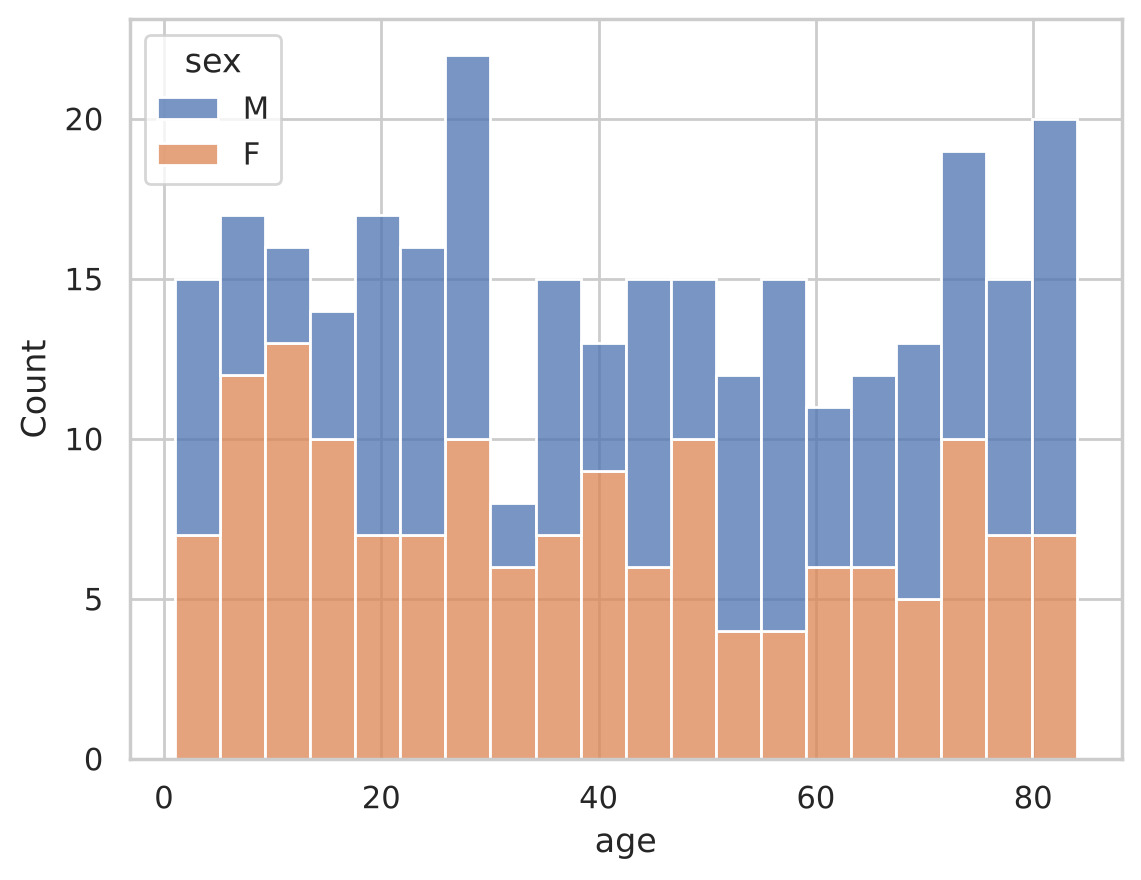

In [2]:
sns.histplot(data=patients, x="age", hue="sex", bins=20, multiple="stack")
plt.show()

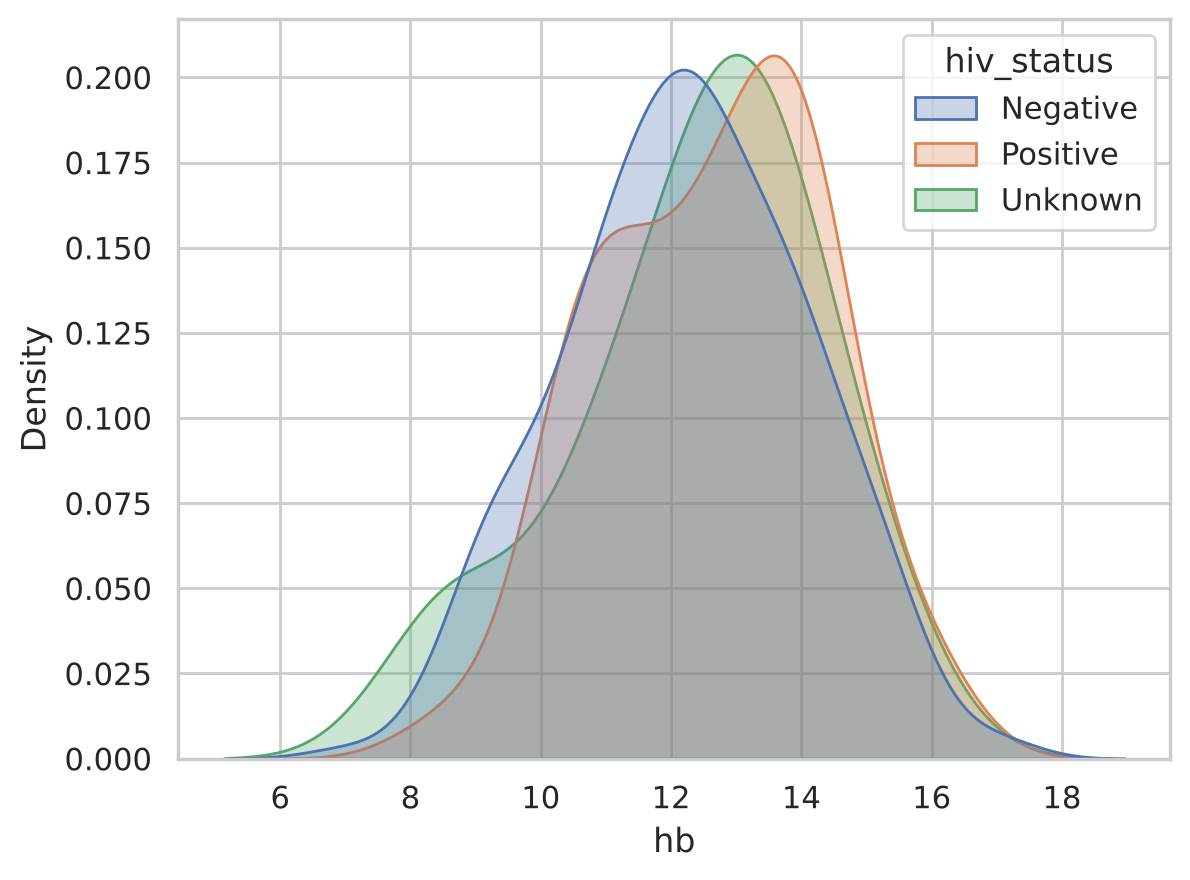

In [3]:
sns.kdeplot(data=df[df["visit"] == 0], x="hb", hue="hiv_status", common_norm=False, fill=True, alpha=0.3)
plt.show()

## Comparing groups

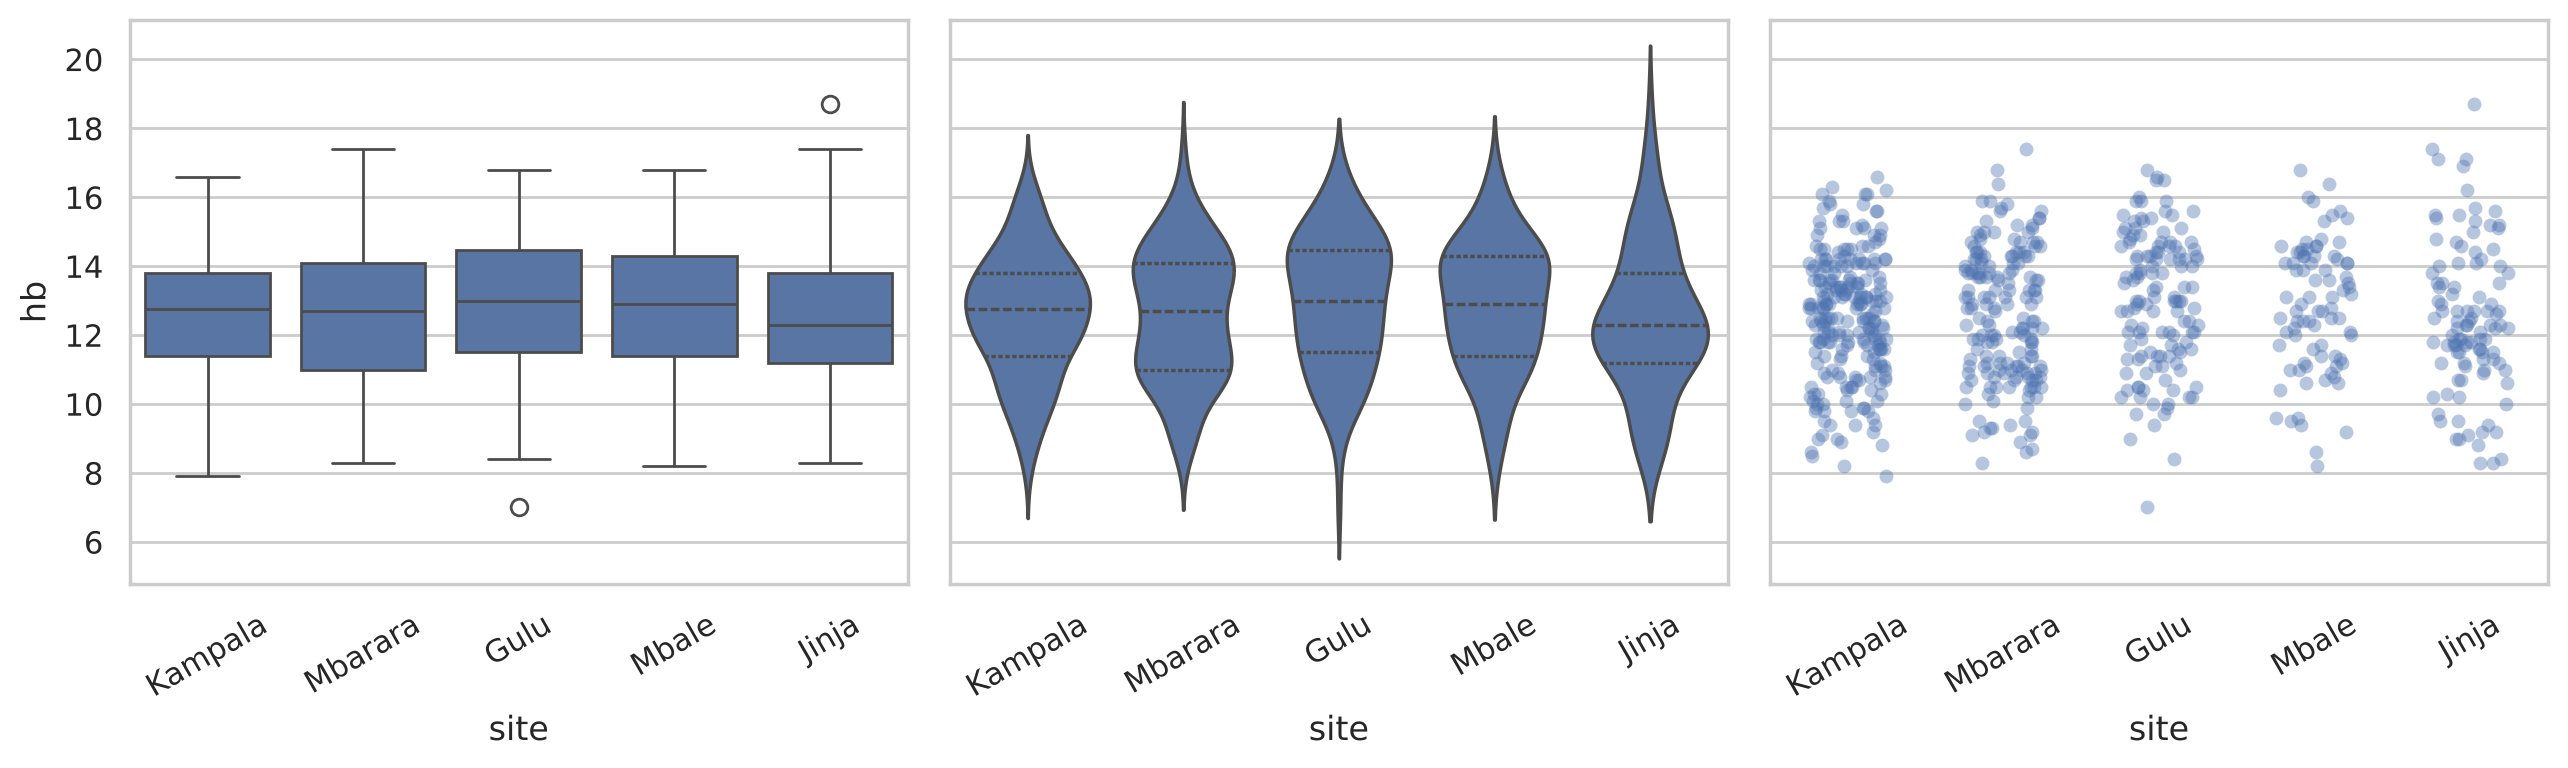

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
sns.boxplot(data=df, x="site", y="hb", ax=axes[0])
sns.violinplot(data=df, x="site", y="hb", ax=axes[1], inner="quart")
sns.stripplot(data=df, x="site", y="hb", ax=axes[2], alpha=0.4, jitter=0.25)
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

Bar plots show a mean with a confidence interval by default:

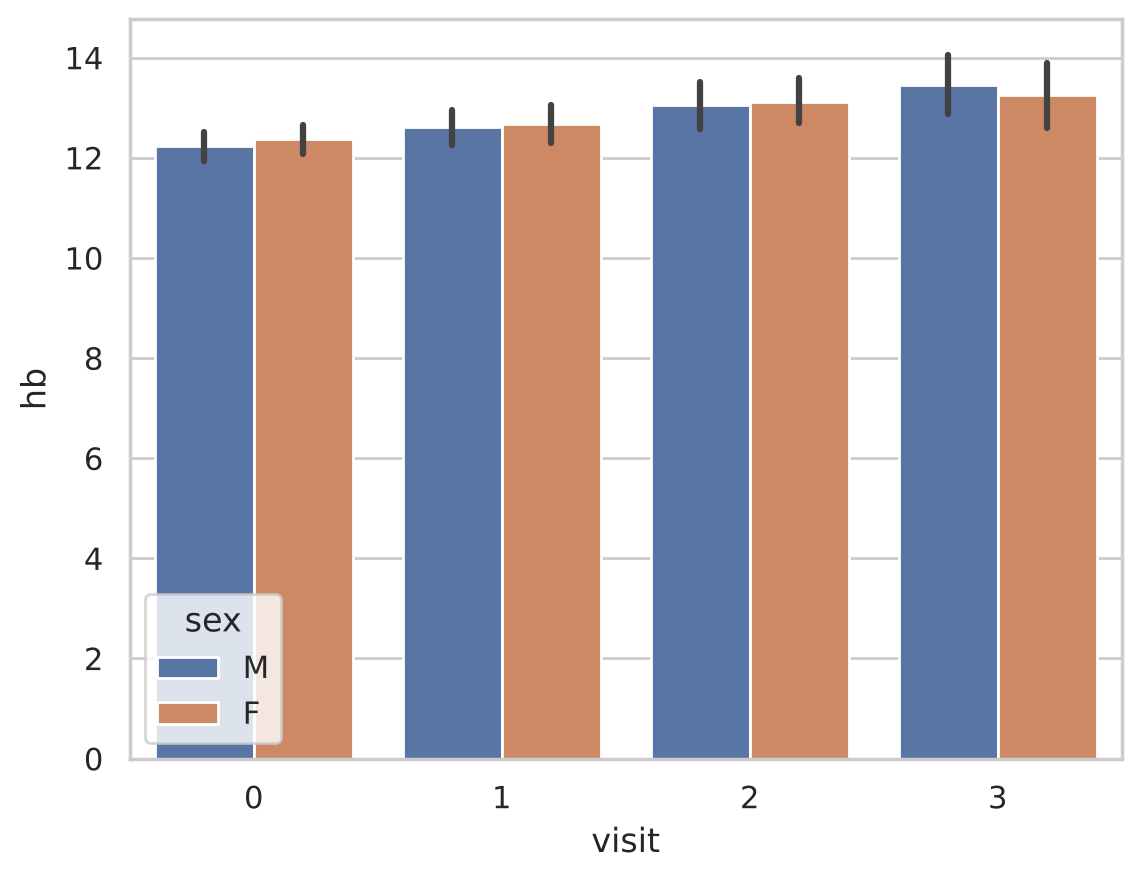

In [5]:
sns.barplot(data=df, x="visit", y="hb", hue="sex", errorbar=("ci", 95))
plt.show()

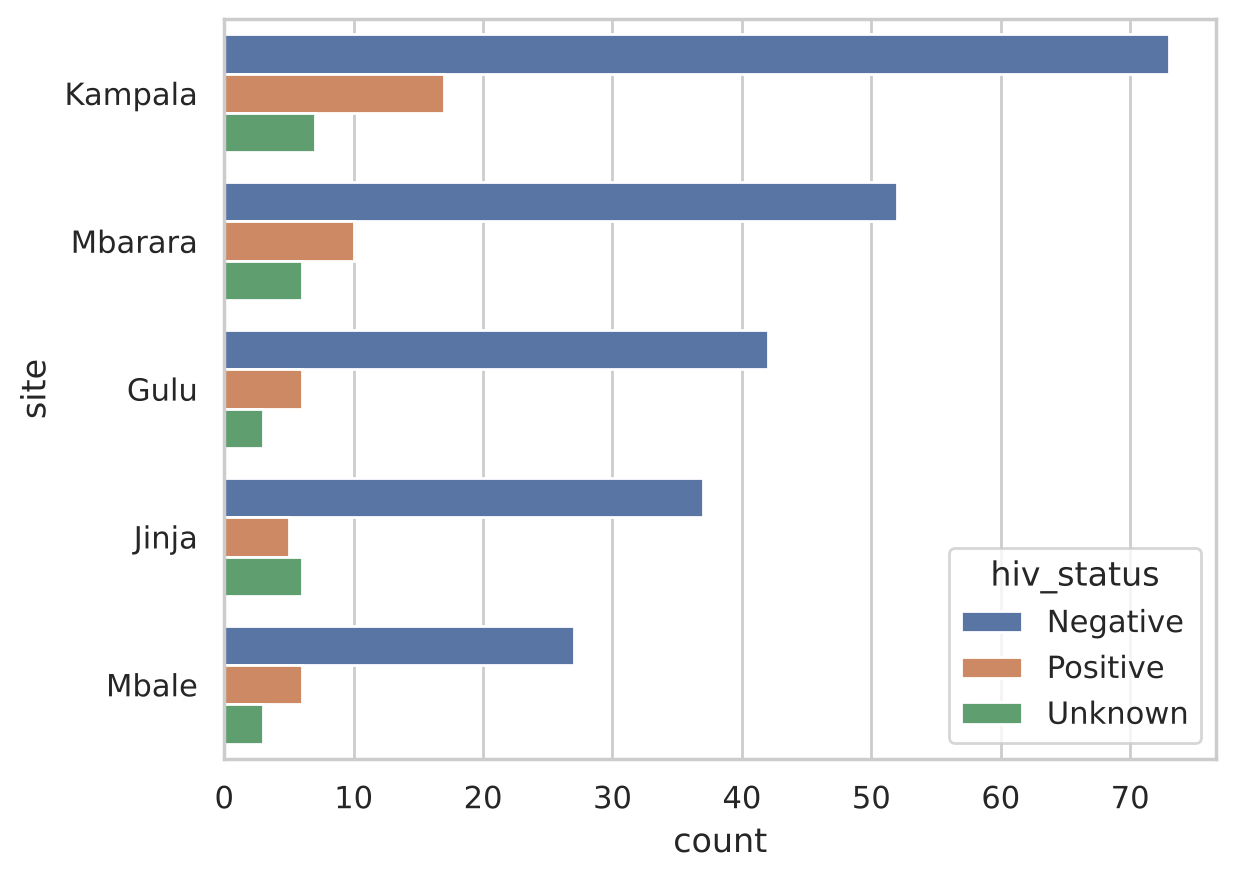

In [6]:
sns.countplot(data=patients, y="site", hue="hiv_status", order=patients["site"].value_counts().index)
plt.show()

## Relationships

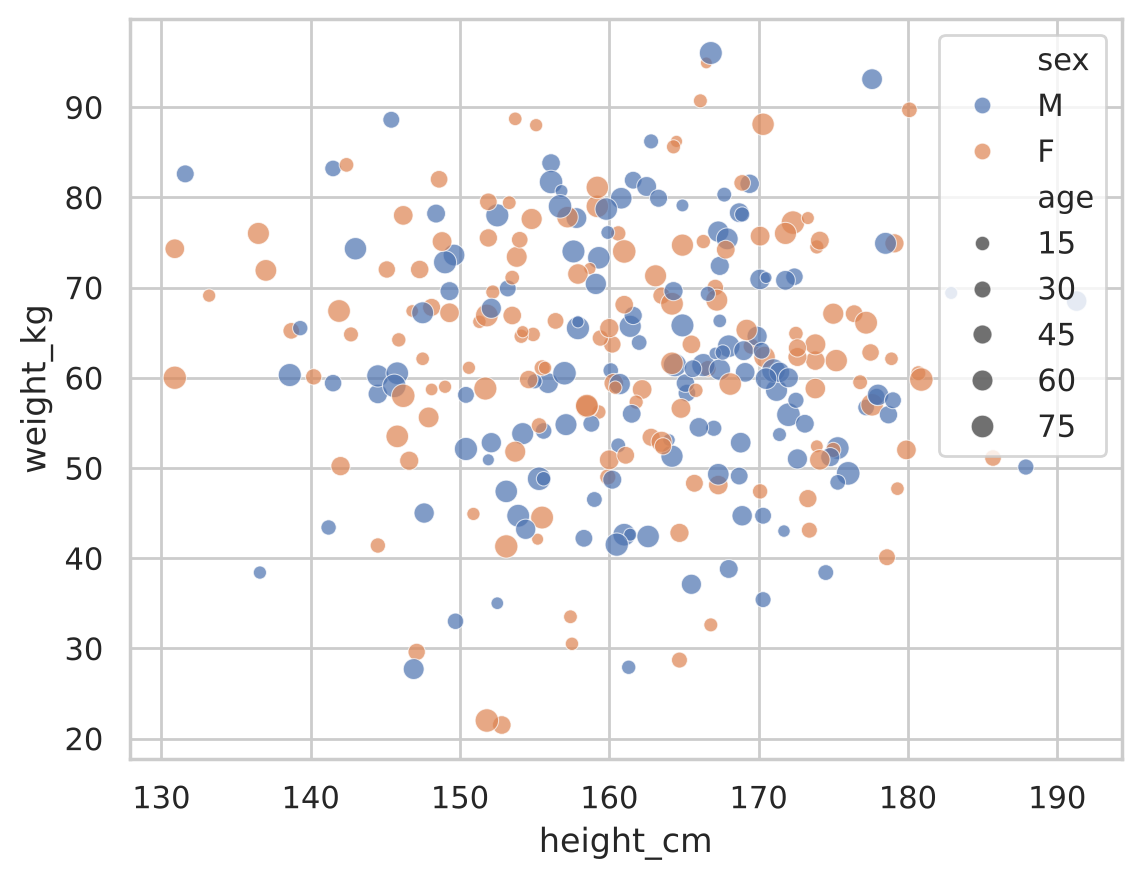

In [7]:
sns.scatterplot(data=patients, x="height_cm", y="weight_kg", hue="sex", size="age", alpha=0.7)
plt.show()

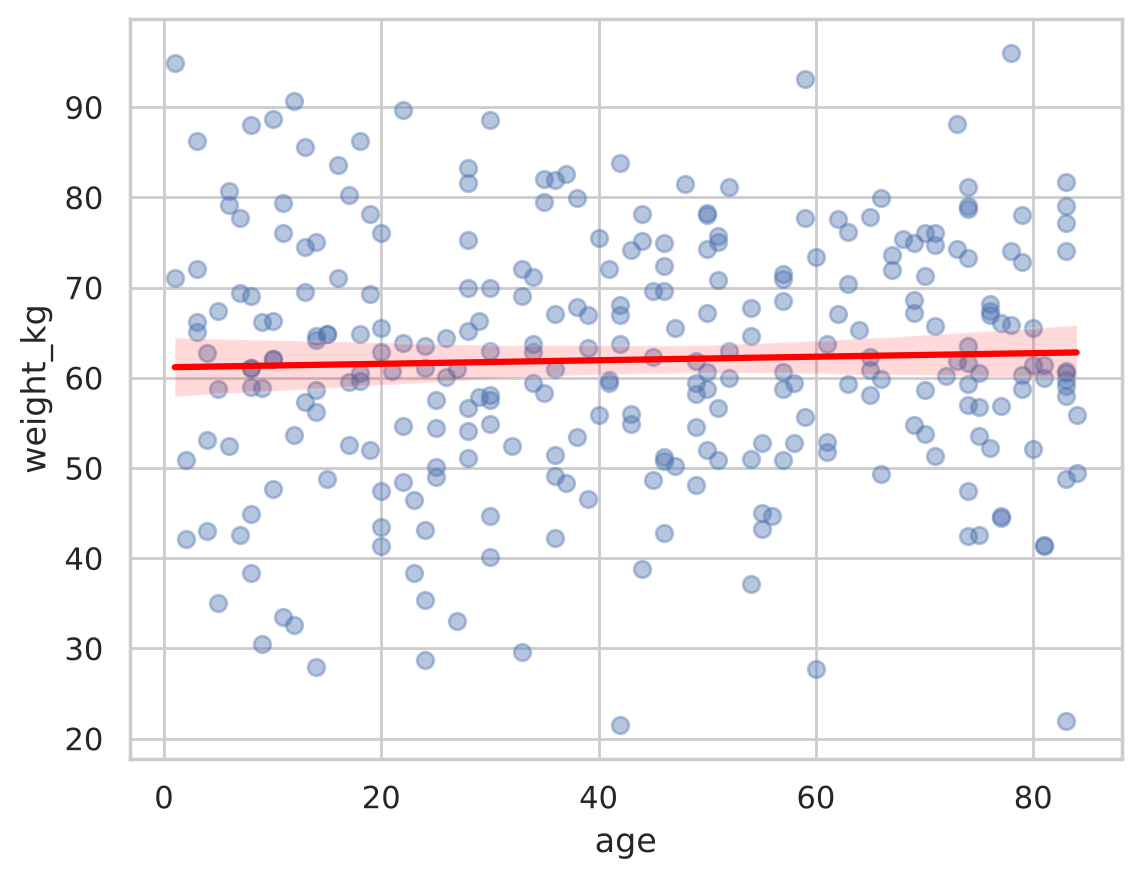

In [8]:
sns.regplot(data=patients, x="age", y="weight_kg", scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.show()

Line plots of repeated measures, with the mean and its interval per visit:

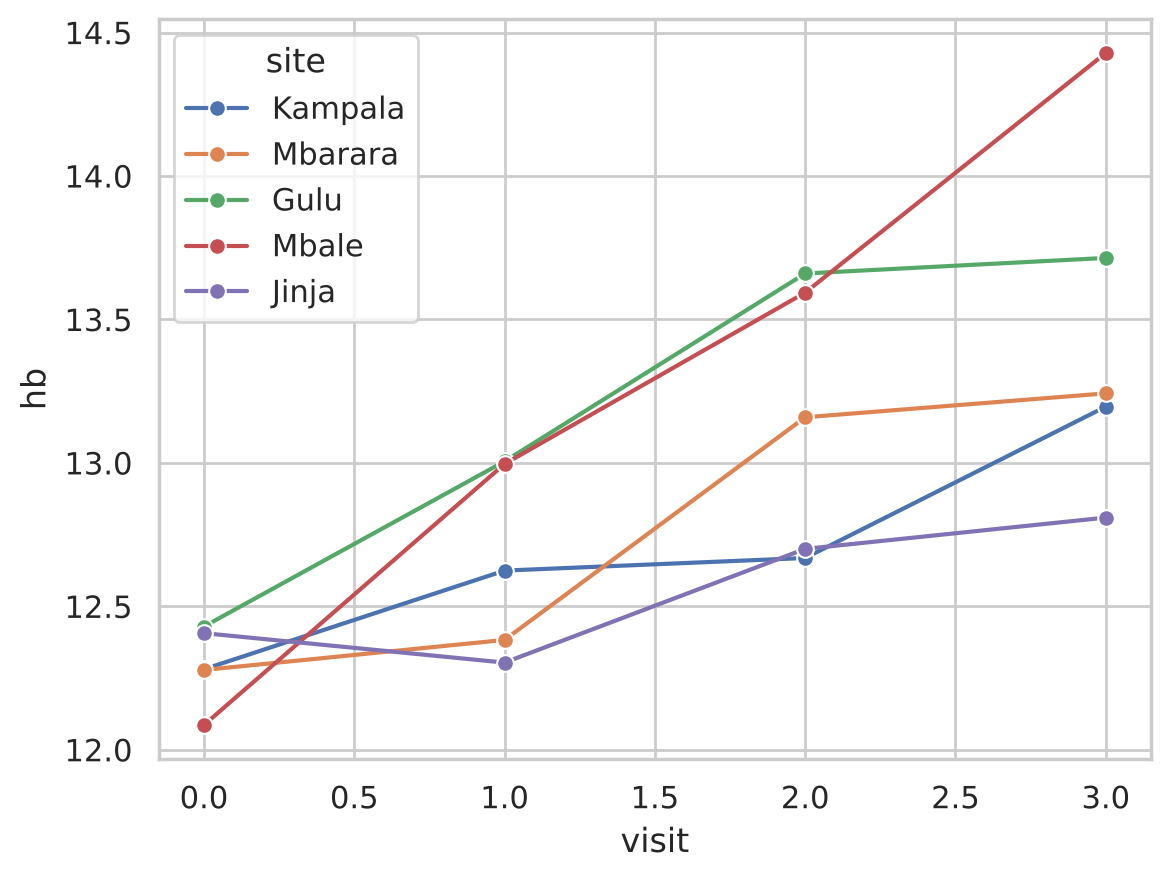

In [9]:
sns.lineplot(data=df, x="visit", y="hb", hue="site", marker="o", errorbar=None)
plt.show()

## Correlation heatmap

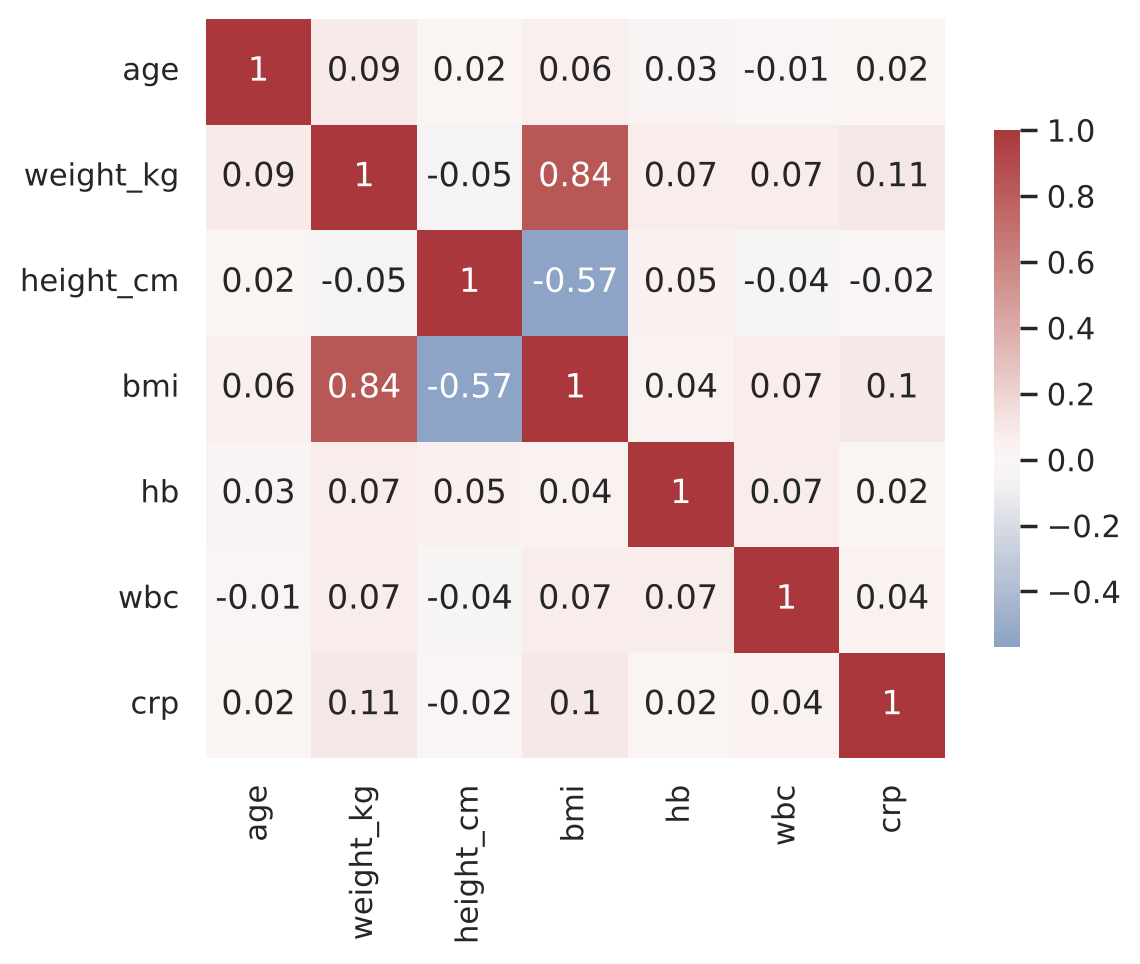

In [10]:
num = df[["age", "weight_kg", "height_cm", "bmi", "hb", "wbc", "crp"]]
corr = num.corr().round(2)
sns.heatmap(corr, annot=True, cmap="vlag", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.show()

## Small multiples

The figure-level functions `relplot`, `displot` and `catplot` split a plot into panels with `col` and `row`.

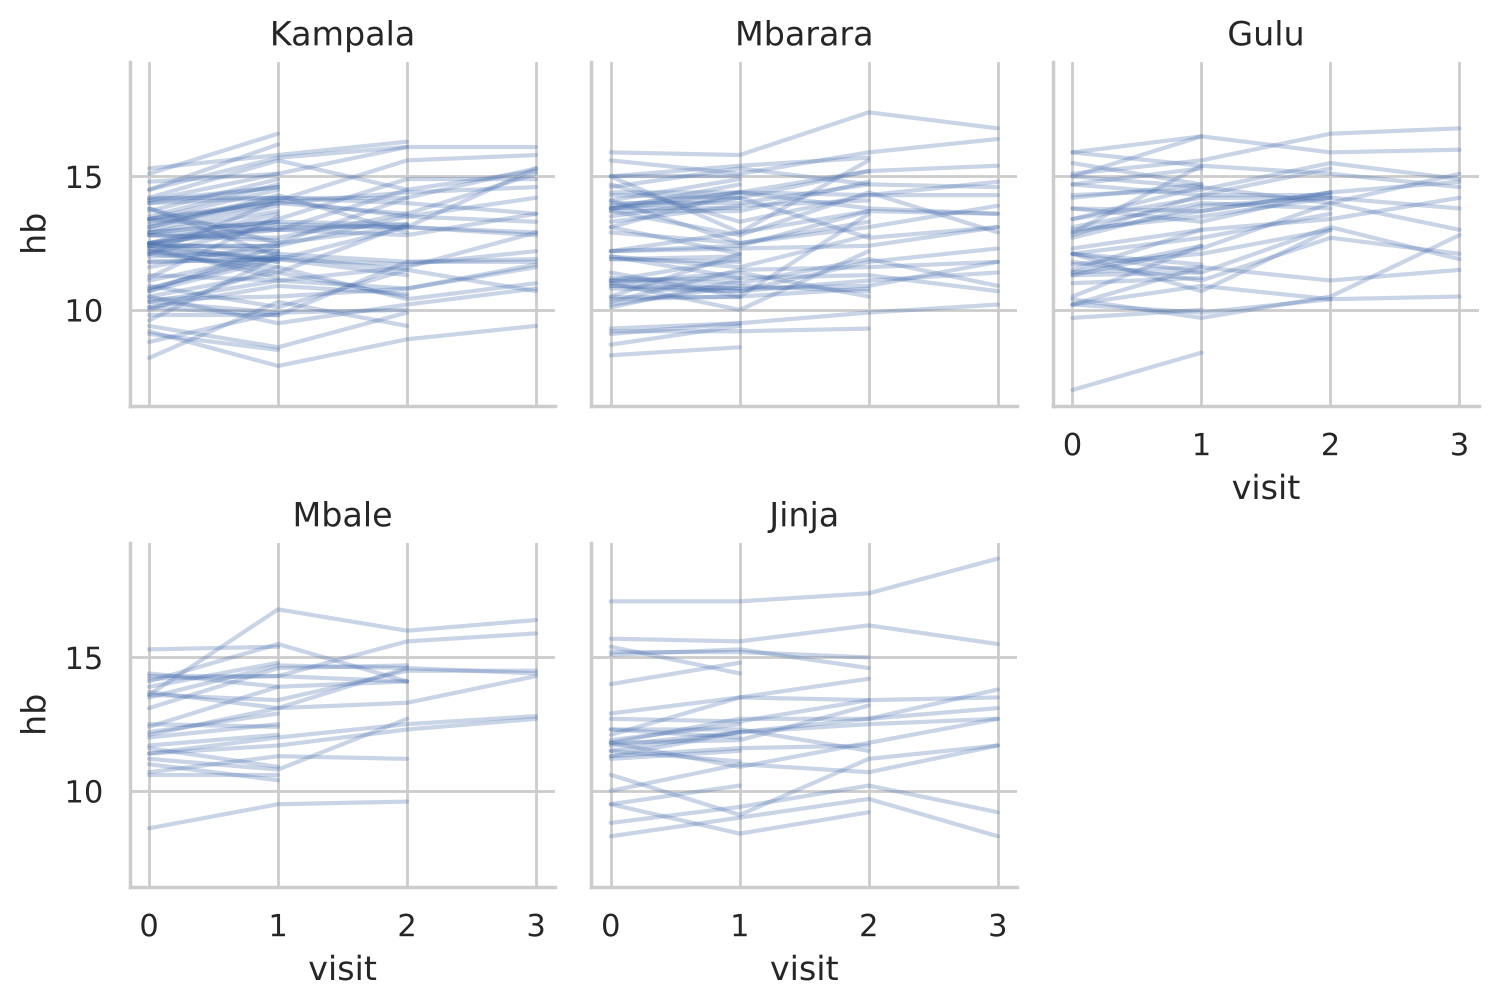

In [11]:
g = sns.relplot(data=df, x="visit", y="hb", col="site", col_wrap=3, kind="line",
                units="patient_id", estimator=None, alpha=0.3, height=2.6)
g.set_titles("{col_name}")
plt.show()

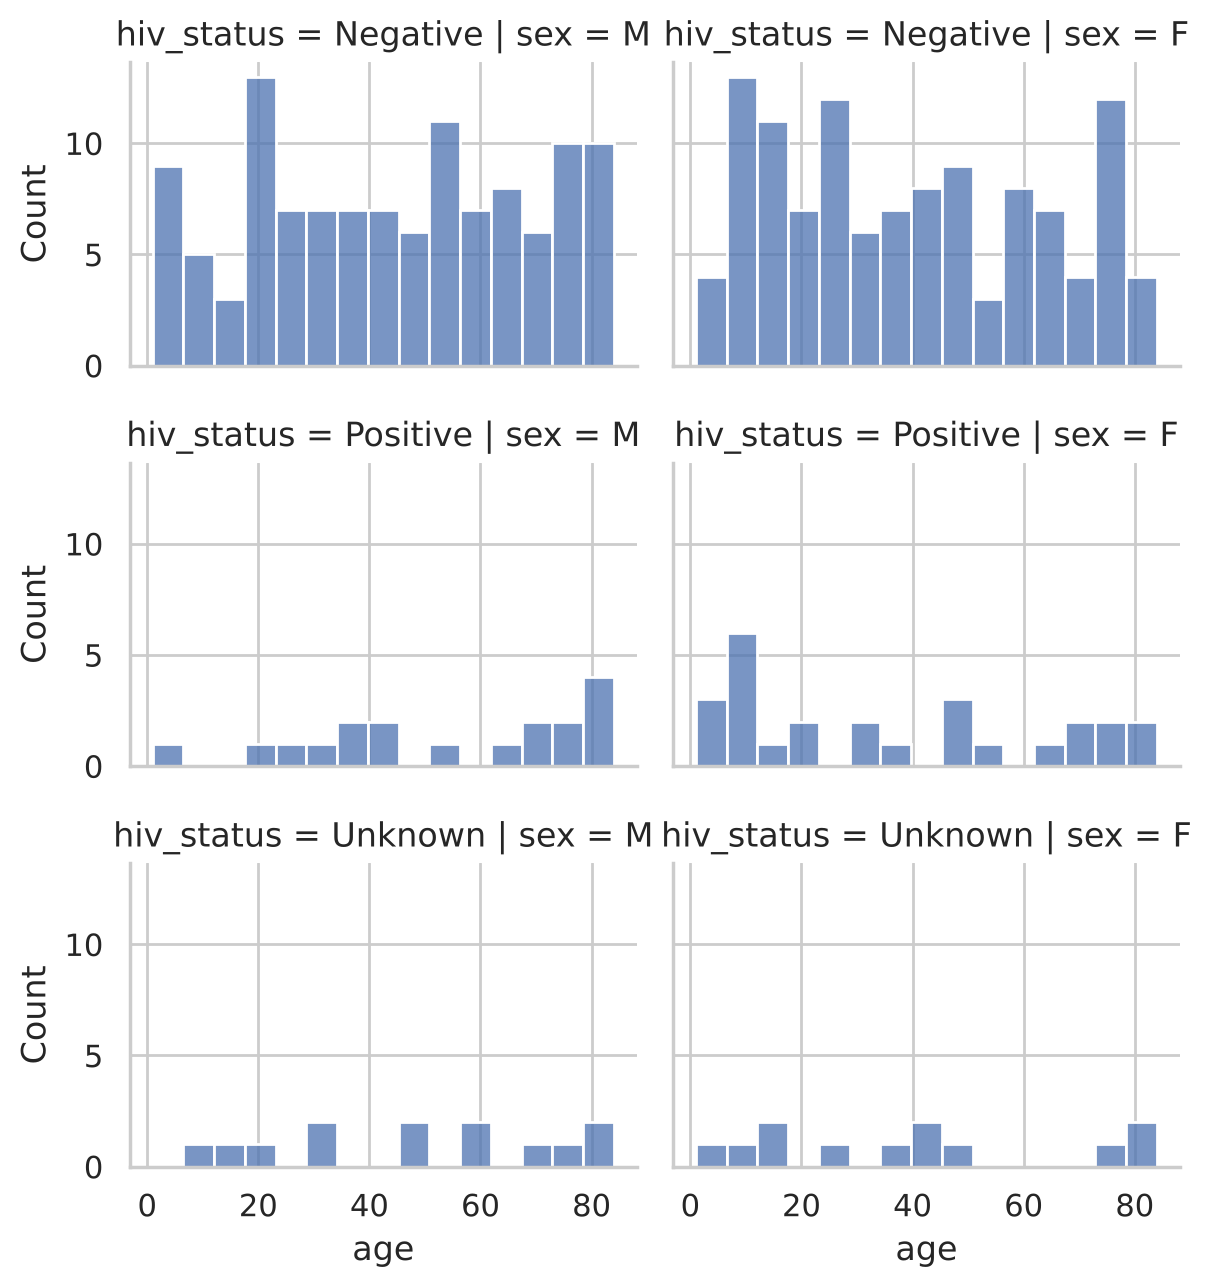

In [12]:
g = sns.displot(data=patients, x="age", col="sex", row="hiv_status", bins=15, height=2.2, aspect=1.4)
plt.show()

## Pair plot

Every numeric variable against every other: a quick first look before modelling.

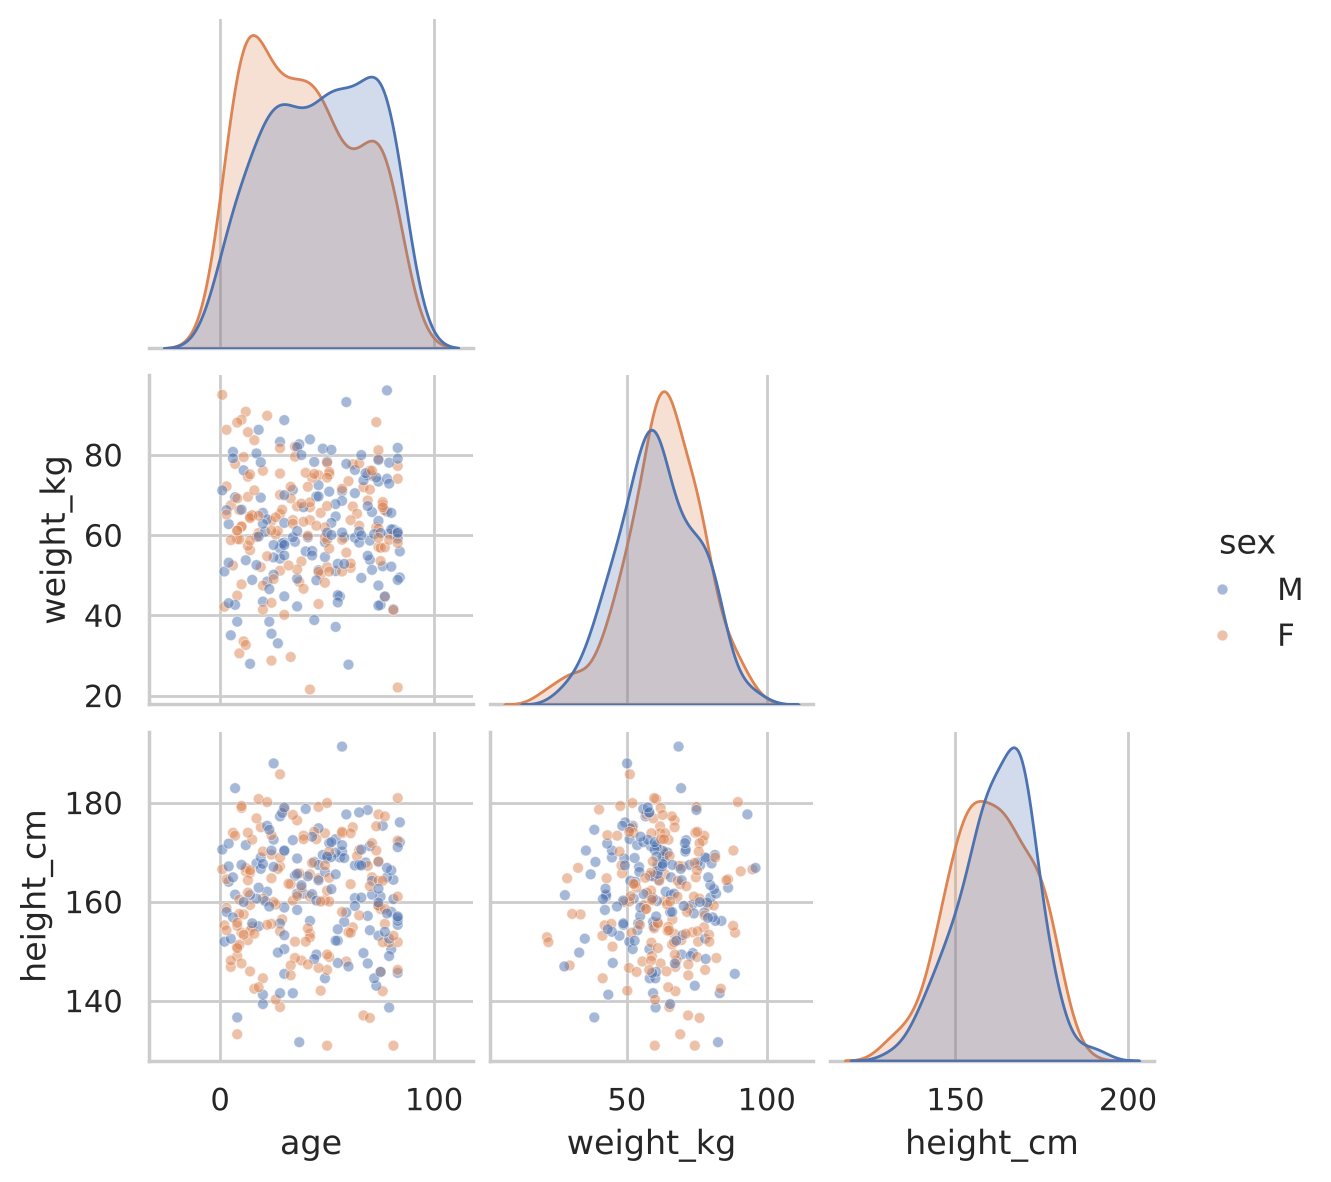

In [13]:
sns.pairplot(patients[["age", "weight_kg", "height_cm", "sex"]].dropna(), hue="sex",
             corner=True, plot_kws={"alpha": 0.5, "s": 15}, height=2)
plt.show()

## Adjusting a seaborn plot

Axes-level functions return a matplotlib `ax`; figure-level ones return a grid `g`
with `g.fig` and `g.axes`.

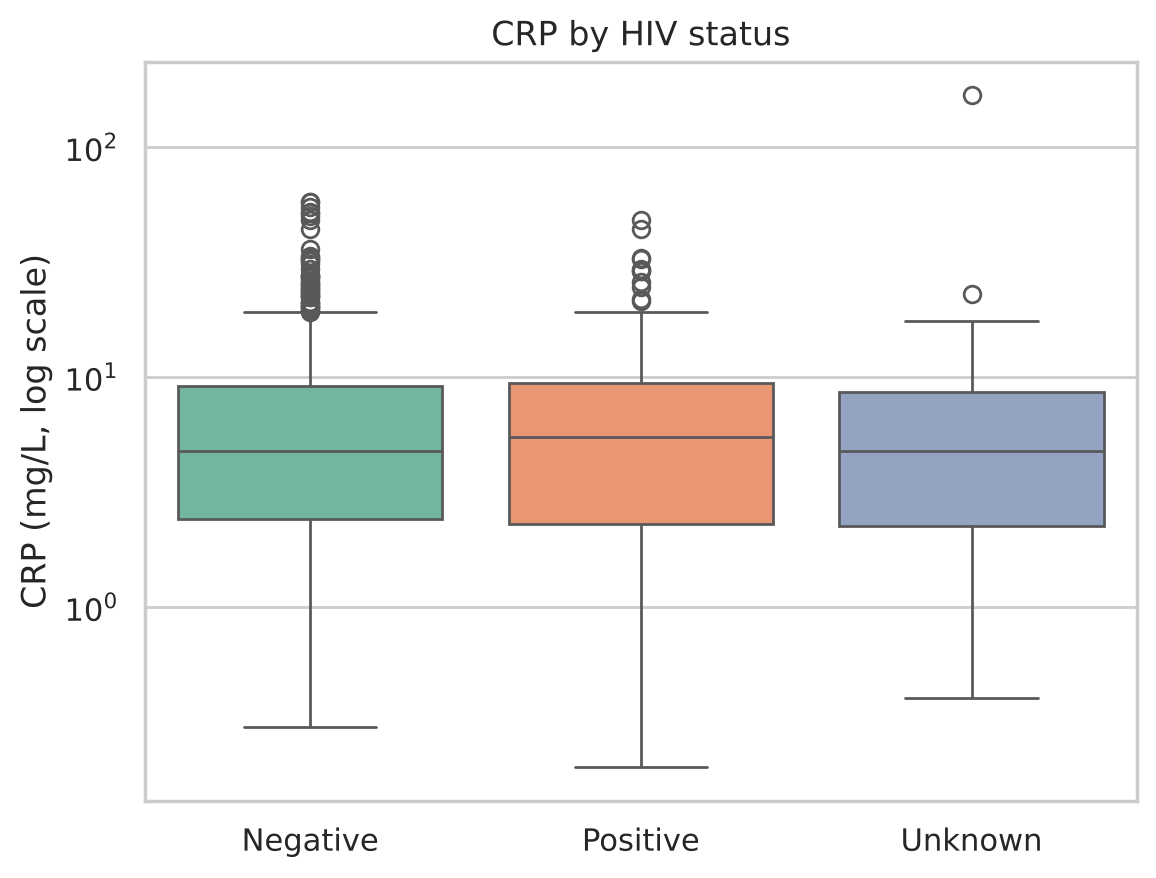

In [14]:
ax = sns.boxplot(data=df, x="hiv_status", y="crp", hue="hiv_status", palette="Set2", legend=False)
ax.set_yscale("log")
ax.set(xlabel="", ylabel="CRP (mg/L, log scale)", title="CRP by HIV status")
plt.show()